# Music Instrument Classification - Mix

## Setup

In [67]:
import os
import json
import numpy as np
import librosa
import pandas as pd
import matplotlib.pyplot as plt
import IPython
import soundfile as sf
from tqdm import tqdm 
from collections import OrderedDict
from sklearn.model_selection import train_test_split
import glob
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import CSVLogger, EarlyStopping, ModelCheckpoint
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics import multilabel_confusion_matrix

Utility function:

In [68]:
def plot_instrument_histogram(instrument_counts, top_n=20, min_count=None, title=''):
    """
    Creates a horizontal histogram with the frequencies of the instruments.
    
    Args:
        instrument_counts: Dictionary with instrument as key and frequency as value
        top_n: Show only the top N most frequent instruments (default 20)
        min_count: Minimum appearance threshold to include an instrument
    """

    # Sort instruments by frequency (highest to lowest)
    sorted_instruments = sorted(instrument_counts.items(), key=lambda x: x[1], reverse=True)
    
    # Filter according to parameters
    filtered_instruments = []
    for instrument, count in sorted_instruments:
        if min_count is not None and count < min_count:
            continue
        filtered_instruments.append((instrument, count))
        if len(filtered_instruments) >= top_n:
            break
    
    # Separate names and counts for the plot
    names = [item[0] for item in filtered_instruments]
    counts = [item[1] for item in filtered_instruments]
    
    # Create figure with size adapted to the number of instruments
    plt.figure(figsize=(16, max(8, len(names) * 0.3)))
    
    # Create horizontal bars
    plt.barh(names, counts, color='skyblue')
    
    # Add labels and title
    plt.xlabel('Number of appearances')
    plt.title(title)
    
    # Adjust margins
    plt.tight_layout()
    
    # Add the numeric value at the end of each bar
    for i, count in enumerate(counts):
        plt.text(count + 0.5, i, str(count), va='center')
    
    # Show the plot
    plt.show()

Custom classes definition and indexing:

In [69]:
# First, we define the mapping we already agreed on
# Mapping from original instruments to grouped categories
instrument_mapping = {
    # Large individual classes
    'electric_bass': 'electric_bass',
    'drum_set': 'drum_set',
    'piano': 'piano',
    'tack_piano': 'piano',
    'synthesizer': 'synthesizer',
    'electric_piano': 'synthesizer',
    'clean_electric_guitar': 'clean_electric_guitar',
    'distorted_electric_guitar': 'distorted_electric_guitar',
    'acoustic_guitar': 'acoustic_guitar',
    'violin': 'violin',
    'female_singer': 'female_singer',
    'vocalists': 'vocalists',
    
    # Male vocals
    'male_singer': 'male_vocals',
    'male_speaker': 'male_vocals',
    'male_rapper': 'male_vocals',
    
    # Other bowed strings
    'viola': 'other_bowed_strings',
    'cello': 'other_bowed_strings',
    'double_bass': 'other_bowed_strings',
    'violin_section': 'other_bowed_strings',
    'viola_section': 'other_bowed_strings',
    'cello_section': 'other_bowed_strings',
    'string_section': 'other_bowed_strings',
    'erhu': 'other_bowed_strings',
    
    # Woodwinds
    'flute': 'woodwinds',
    'clarinet': 'woodwinds',
    'oboe': 'woodwinds',
    'bassoon': 'woodwinds',
    'tenor_saxophone': 'woodwinds',
    'soprano_saxophone': 'woodwinds',
    'alto_saxophone': 'woodwinds',
    'baritone_saxophone': 'woodwinds',
    'bass_clarinet': 'woodwinds',
    'piccolo': 'woodwinds',
    'flute_section': 'woodwinds',
    'clarinet_section': 'woodwinds',
    
    # Brass
    'trumpet': 'brass',
    'trombone': 'brass',
    'french_horn': 'brass',
    'french_horn_section': 'brass',
    'brass_section': 'brass',
    'tuba': 'brass',
    'horn_section': 'brass',
    'trumpet_section': 'brass',
    
    # Other percussion
    'auxiliary_percussion': 'other_percussion',
    'tambourine': 'other_percussion',
    'cymbals': 'other_percussion',
    'timpani': 'other_percussion',
    'tabla': 'other_percussion',
    'shaker': 'other_percussion',
    'snare_drum': 'other_percussion',
    'bass_drum': 'other_percussion',
    'kick_drum': 'other_percussion',
    'bongo': 'other_percussion',
    'darbuka': 'other_percussion',
    'doumbek': 'other_percussion',
    'gong': 'other_percussion',
    'toms': 'other_percussion',
    'drum_machine': 'other_percussion',
    'claps': 'other_percussion',
    'chimes': 'other_percussion',
    
    # Other plucked strings
    'mandolin': 'other_plucked_strings',
    'banjo': 'other_plucked_strings',
    'guzheng': 'other_plucked_strings',
    'oud': 'other_plucked_strings',
    'harp': 'other_plucked_strings',
    'lap_steel_guitar': 'other_plucked_strings',
    'yangqin': 'other_plucked_strings',
    'zhongruan': 'other_plucked_strings',
    'glockenspiel': 'other_plucked_strings',
    'vibraphone': 'other_plucked_strings',
    
    # Reed instruments
    'accordion': 'reed_instruments',
    'harmonica': 'reed_instruments',
    'melodica': 'reed_instruments',
    
    # Effects and processed sounds
    'fx_slash_processed_sound': 'fx_and_processed',
    'scratches': 'fx_and_processed'
}

# List of instruments to completely discard
instruments_to_discard = [
    'sampler',
    'main_system',
    'trombone_section',
]

# Final categories
instrument_categories = [
    'electric_bass',
    'drum_set',
    'piano',
    'synthesizer',
    'clean_electric_guitar',
    'distorted_electric_guitar',
    'acoustic_guitar',
    'violin',
    'female_singer',
    'vocalists',
    'male_vocals',
    'other_bowed_strings',
    'woodwinds',
    'brass',
    'other_percussion',
    'other_plucked_strings',
    'reed_instruments',
    'fx_and_processed'
]

# Mapping from categories to indices
category_to_idx = {category: idx for idx, category in enumerate(instrument_categories)}

Loading features and labels:

In [ ]:
mel_features = np.load("extracted_mix_features/all_mels.npy")
cqt_features = np.load("extracted_mix_features/all_cqts.npy")
labels = np.load("extracted_mix_features/all_labels.npy")

Showing the instrument distribution in the MedleyDB mixes:

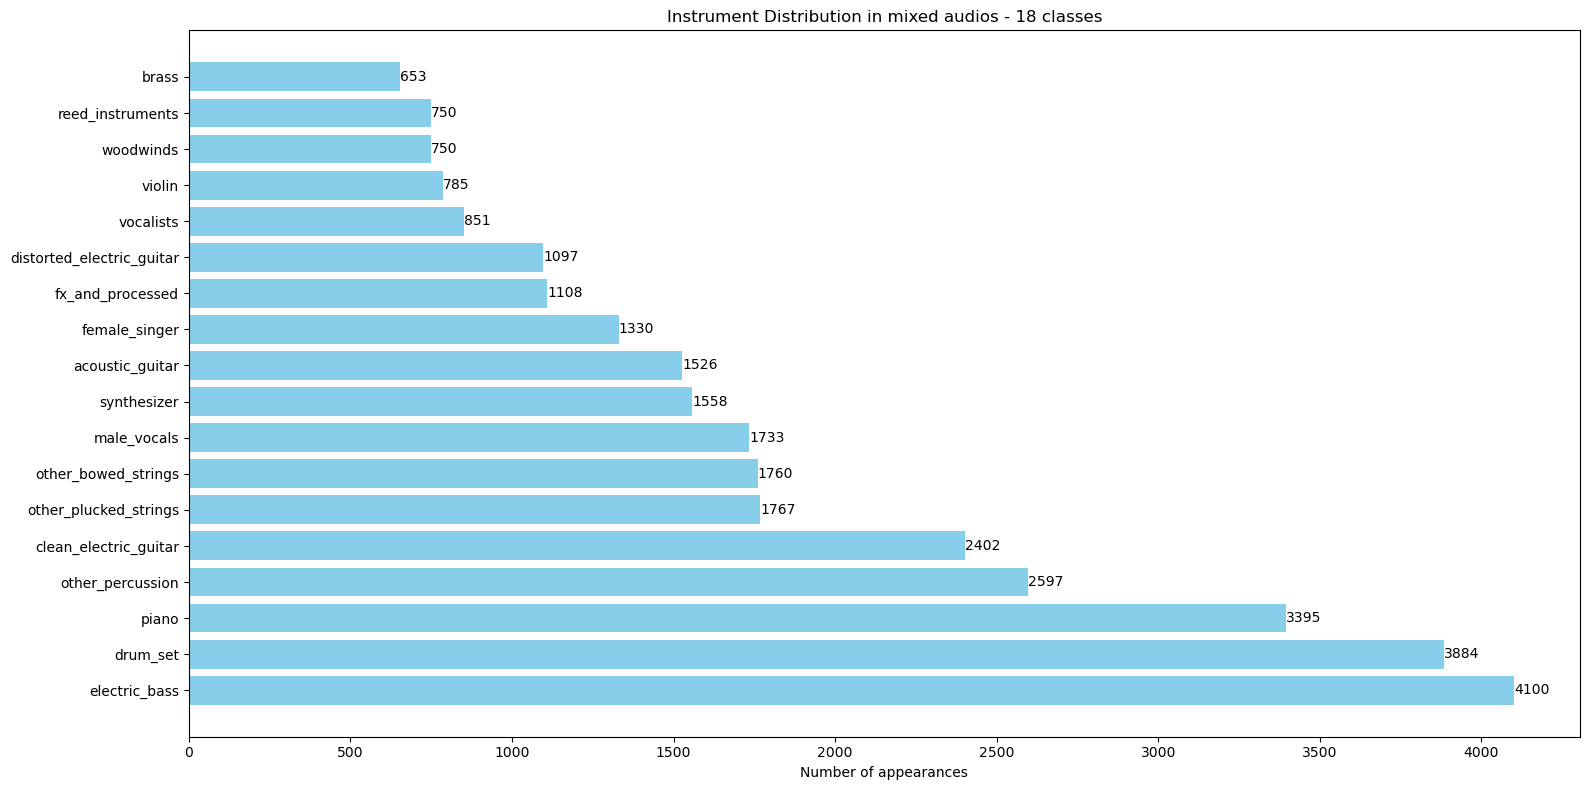

In [71]:
# Count the number of samples
class_counts = np.sum(labels, axis=0)

# Create a dictionary to hold the counts for each instrument category
category_counts = {label: int(count) for label, count in zip(instrument_categories, class_counts)}

# Plot the histogram of instrument frequencies
plot_instrument_histogram(category_counts, top_n=np.shape(labels)[1], title='Instrument Distribution in mixed audios - 18 classes')

Data splitting and normalization:

In [72]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    cqt_features, labels, test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

print(f"Loaded data: {cqt_features.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

# Normalize the data
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (9154, 96, 130)


## Model 1

The biggest model in terms of trainable parameters:

| Layer Type         | Details                                                        |
|:-------------------|:--------------------------------------------------------------|
| Input              | Input shape: (96, 130, 1)                                      |
| Conv2D             | Filters: **32**, Kernel: 3x3, Activation: relu                 |
| MaxPooling2D       | Pool size: 2x2                                                |
| Conv2D             | Filters: **64**, Kernel: 3x3, Activation: relu                 |
| MaxPooling2D       | Pool size: 2x2                                                |
| Conv2D             | Filters: **128**, Kernel: 3x3, Activation: relu                |
| GlobalAveragePooling2D |                                                                |
| Dense              | Units: **64**, Activation: relu                                |
| Dense              | Units: 18, Activation: sigmoid (multilabel output)             |

In [ ]:
# 2D-CNN model for multi-label classification
input_shape = (X_train.shape[1], X_train.shape[2], 1)
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='sigmoid')
])

# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

# Print model summary
model.summary()

Model: "sequential_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_20 (Conv2D)          (None, 94, 128, 32)       320       
                                                                 
 max_pooling2d_18 (MaxPoolin  (None, 47, 64, 32)       0         
 g2D)                                                            
                                                                 
 conv2d_21 (Conv2D)          (None, 45, 62, 64)        18496     
                                                                 
 max_pooling2d_19 (MaxPoolin  (None, 22, 31, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_22 (Conv2D)          (None, 20, 29, 128)       73856     
                                                                 
 global_average_pooling2d_9   (None, 128)             

Training the model and saving history and weights in the files `training_model_mix.log` and `best_model_mix.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [74]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_mix.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=20)

model_name = 'best_model_mix.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_mix.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=20)\n\nmodel_name = 'best_model_mix.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=300,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 1 history:

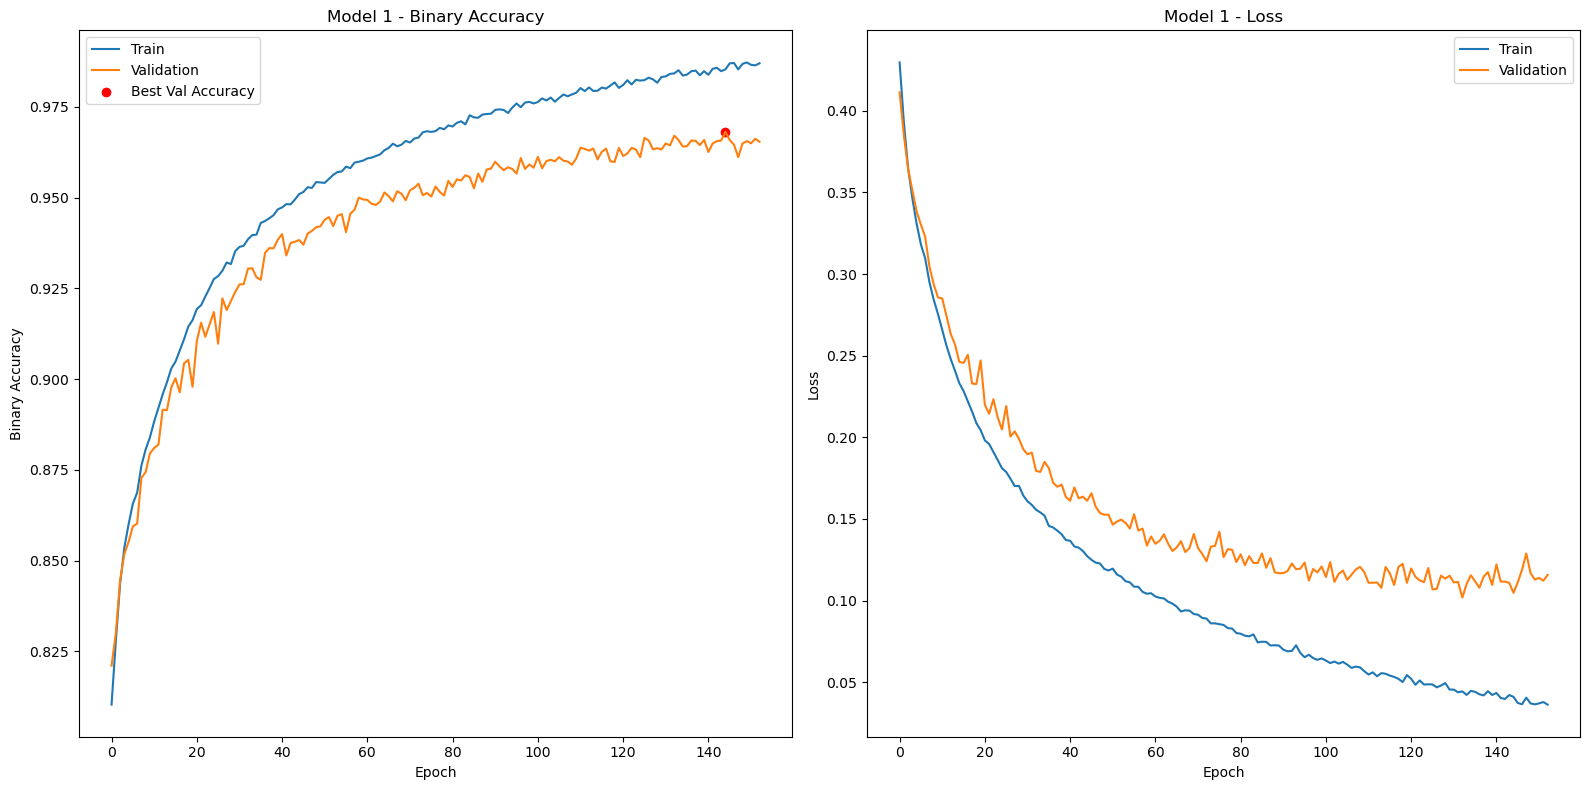

In [75]:
# History plot
log_df = pd.read_csv('training_model_mix.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 1 - Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 1 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 1 confusion matrixes:

29/29 [==============================] - 0s 3ms/step


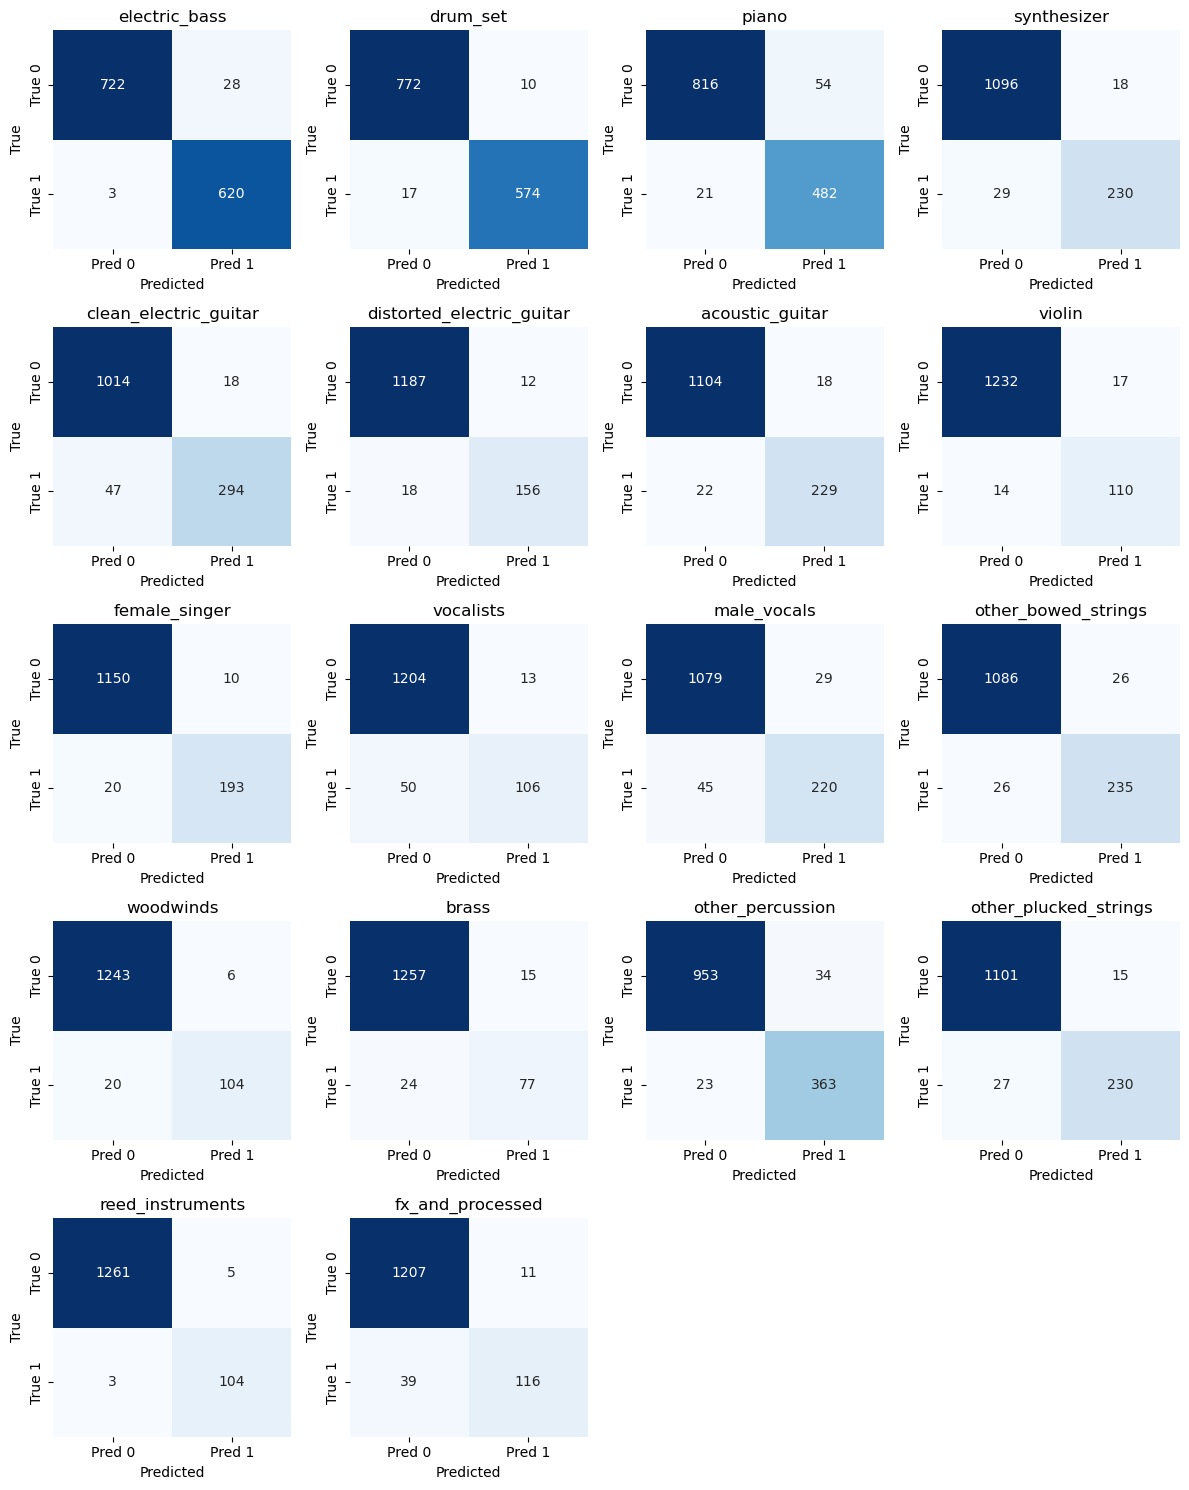

In [76]:
# Load the best model weights
model.load_weights('best_model_mix.h5')

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

# Plot
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

Showing model 1 classification reports:

In [77]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98       623
           1       0.98      0.97      0.98       591
           2       0.90      0.96      0.93       503
           3       0.93      0.89      0.91       259
           4       0.94      0.86      0.90       341
           5       0.93      0.90      0.91       174
           6       0.93      0.91      0.92       251
           7       0.87      0.89      0.88       124
           8       0.95      0.91      0.93       213
           9       0.89      0.68      0.77       156
          10       0.88      0.83      0.86       265
          11       0.90      0.90      0.90       261
          12       0.95      0.84      0.89       124
          13       0.84      0.76      0.80       101
          14       0.91      0.94      0.93       386
          15       0.94      0.89      0.92       257
          16       0.95      0.97      0.96       107
          17       0.91    

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Model 2

Reducing the model architecture size:

| Layer Type         | Details                                                        |
|:-------------------|:--------------------------------------------------------------|
| Input              | Input shape: (96, 130, 1)                                      |
| Conv2D             | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization |                                                                |
| MaxPooling2D       | Pool size: 2x2                                                |
| Conv2D             | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization |                                                                |
| MaxPooling2D       | Pool size: 2x2                                                |
| GlobalAveragePooling2D |                                                           |
| Dense              | Units: **64**, Activation: relu                                |
| Dropout            | Rate: 0.4                                                      |
| Dense              | Units: 18, Activation: sigmoid                                 |

In [78]:
# 2D-CNN model for multi-label classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'), 
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='sigmoid')
])

# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

# Print model summary
model.summary()

Model: "sequential_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_23 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_14 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_20 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_24 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_15 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                     

Training the model and saving history and weights in the files `training_model_mix_smaller.log` and `best_model_mix_smaller.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [79]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_mix_smaller.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=50)

model_name = 'best_model_mix_smaller.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_mix_smaller.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=50)\n\nmodel_name = 'best_model_mix_smaller.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=300,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 2 history:

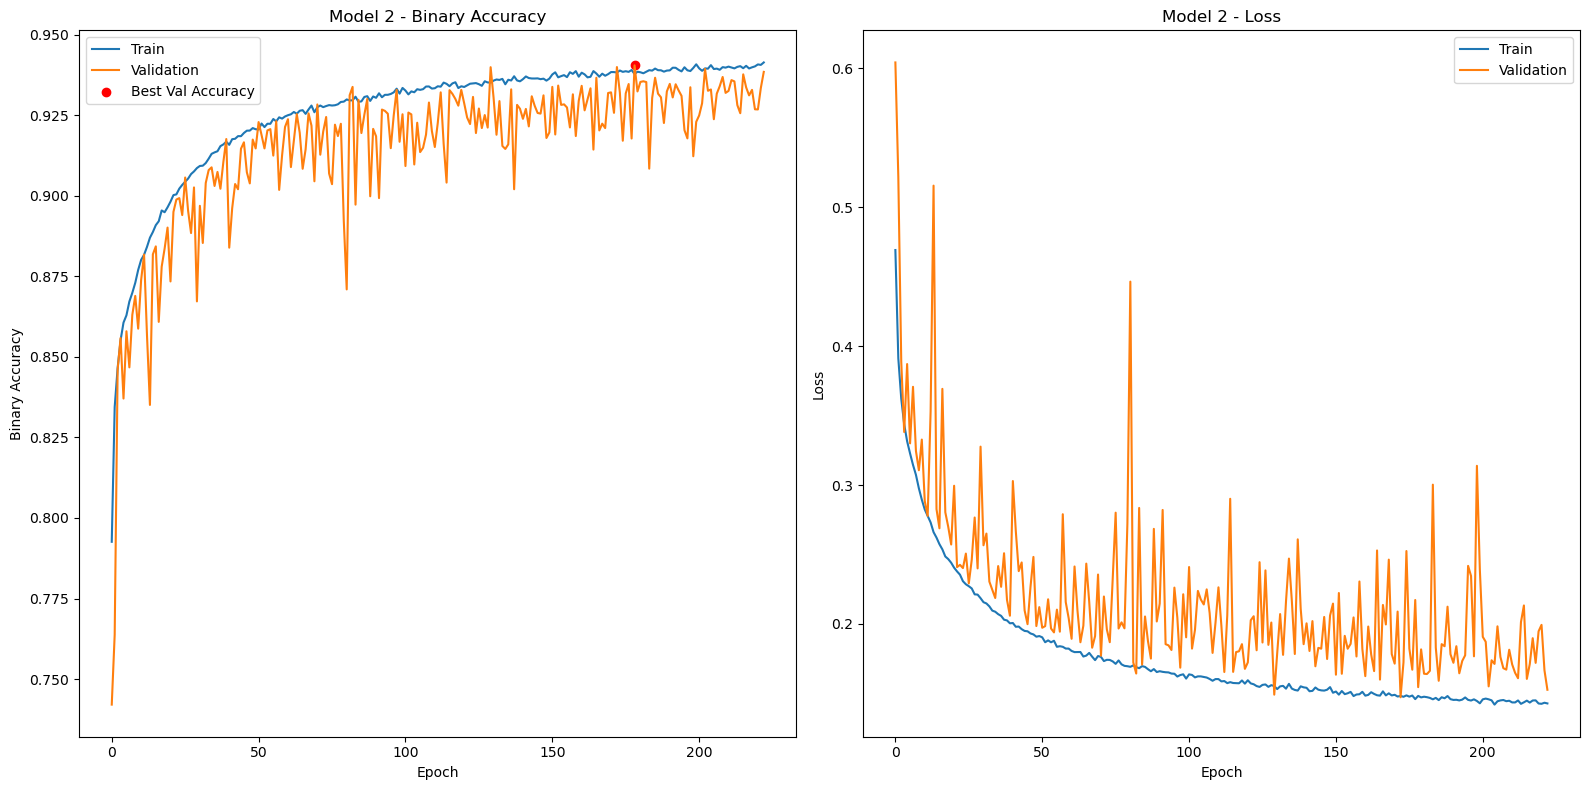

In [80]:
# History plot
log_df = pd.read_csv('training_model_mix_smaller.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 2 - Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 2 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 2 confusion matrixes:

29/29 [==============================] - 0s 3ms/step


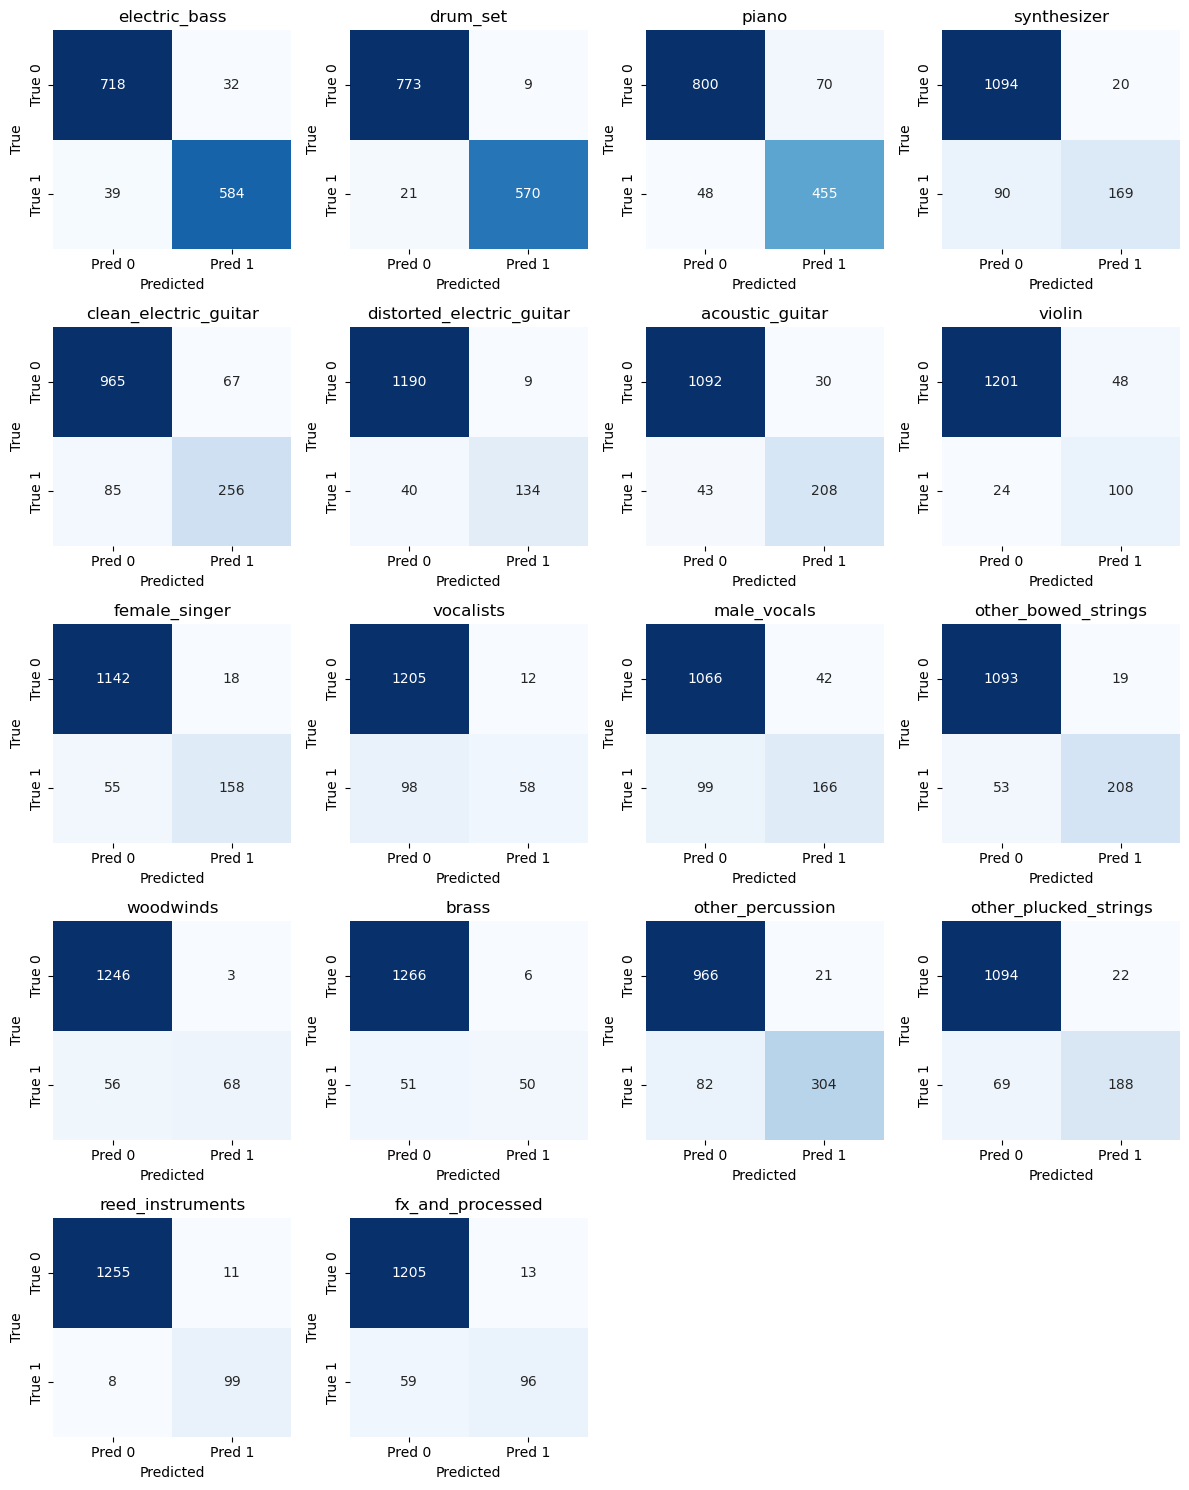

In [81]:
# Load the best model weights
model.load_weights('best_model_mix_smaller.h5')

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

# Plot
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

Showing model 2 classification reports:

In [82]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.95      0.94      0.94       623
           1       0.98      0.96      0.97       591
           2       0.87      0.90      0.89       503
           3       0.89      0.65      0.75       259
           4       0.79      0.75      0.77       341
           5       0.94      0.77      0.85       174
           6       0.87      0.83      0.85       251
           7       0.68      0.81      0.74       124
           8       0.90      0.74      0.81       213
           9       0.83      0.37      0.51       156
          10       0.80      0.63      0.70       265
          11       0.92      0.80      0.85       261
          12       0.96      0.55      0.70       124
          13       0.89      0.50      0.64       101
          14       0.94      0.79      0.86       386
          15       0.90      0.73      0.81       257
          16       0.90      0.93      0.91       107
          17       0.88    

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Model 3

Changing features from cqt to mel: data splitting and normalization.

In [83]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    mel_features, labels, test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

print(f"Loaded data: {mel_features.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

# Normalize the data
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (9154, 96, 130)


Using the same architecture of model 2:

| Layer Type         | Details                                                        |
|:-------------------|:--------------------------------------------------------------|
| Input              | Input shape: (96, 130, 1)                                      |
| Conv2D             | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization |                                                                |
| MaxPooling2D       | Pool size: 2x2                                                |
| Conv2D             | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same  |
| BatchNormalization |                                                                |
| MaxPooling2D       | Pool size: 2x2                                                |
| GlobalAveragePooling2D |                                                           |
| Dense              | Units: **64**, Activation: relu                                |
| Dropout            | Rate: 0.4                                                      |
| Dense              | Units: 18, Activation: sigmoid (multilabel output)             |

In [ ]:
# 2D-CNN model for multi-label classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(instrument_categories)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'), 
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='sigmoid')
])

# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

# Print model summary
model.summary()

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_25 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_16 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_22 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_26 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_17 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                     

Training the model and saving history and weights in the files `training_model_mix_mel.log` and `best_model_mix_mel.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [85]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_mix_mel.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=50)

model_name = 'best_model_mix_mel.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=300,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_mix_mel.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=50)\n\nmodel_name = 'best_model_mix_mel.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=300,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 3 history:

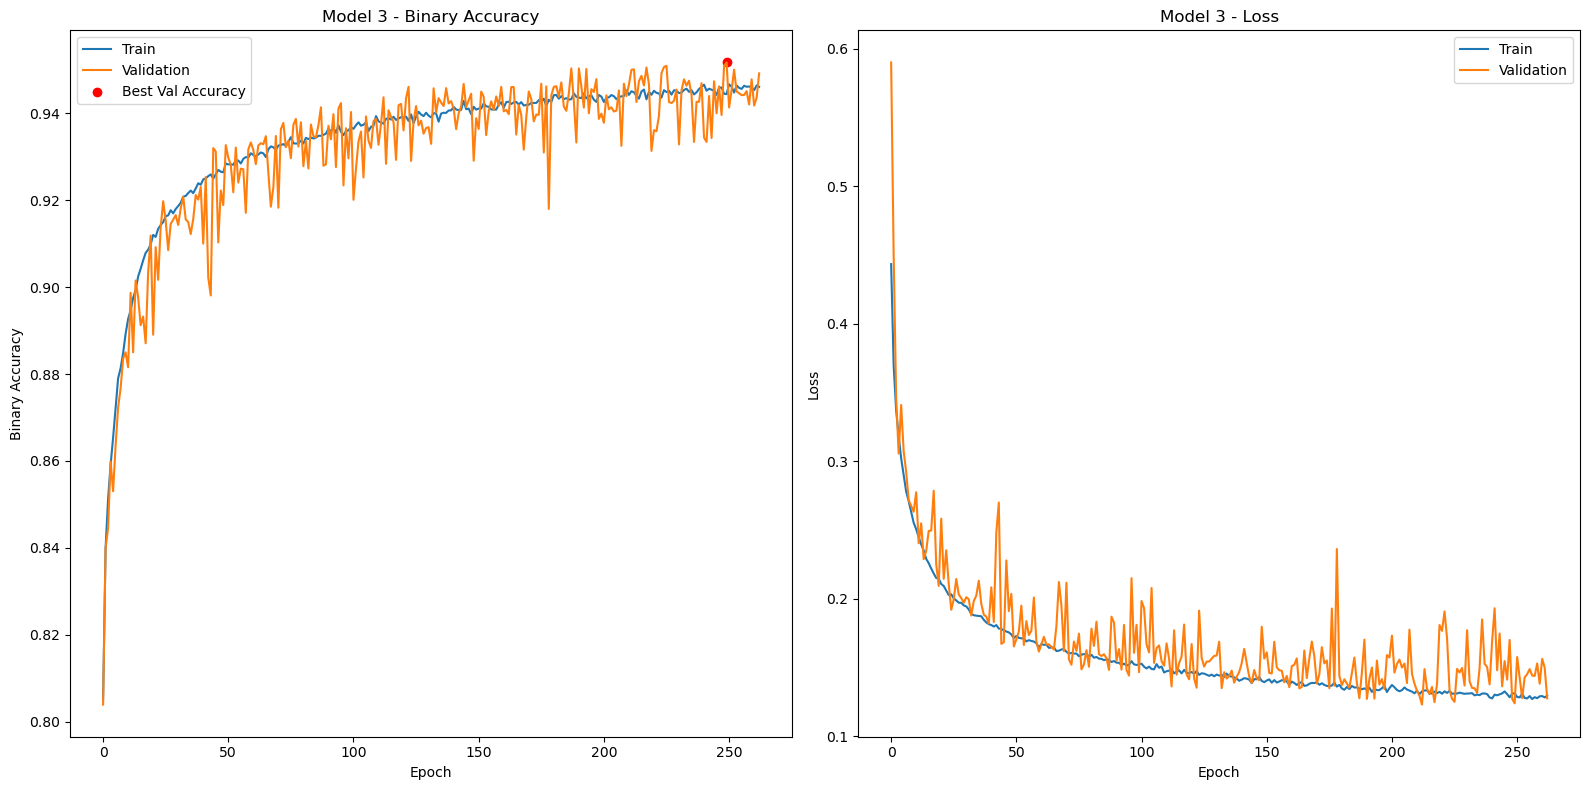

In [86]:
# History plot
log_df = pd.read_csv('training_model_mix_mel.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 3 - Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 3 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 3 confusion matrixes:

29/29 [==============================] - 0s 2ms/step


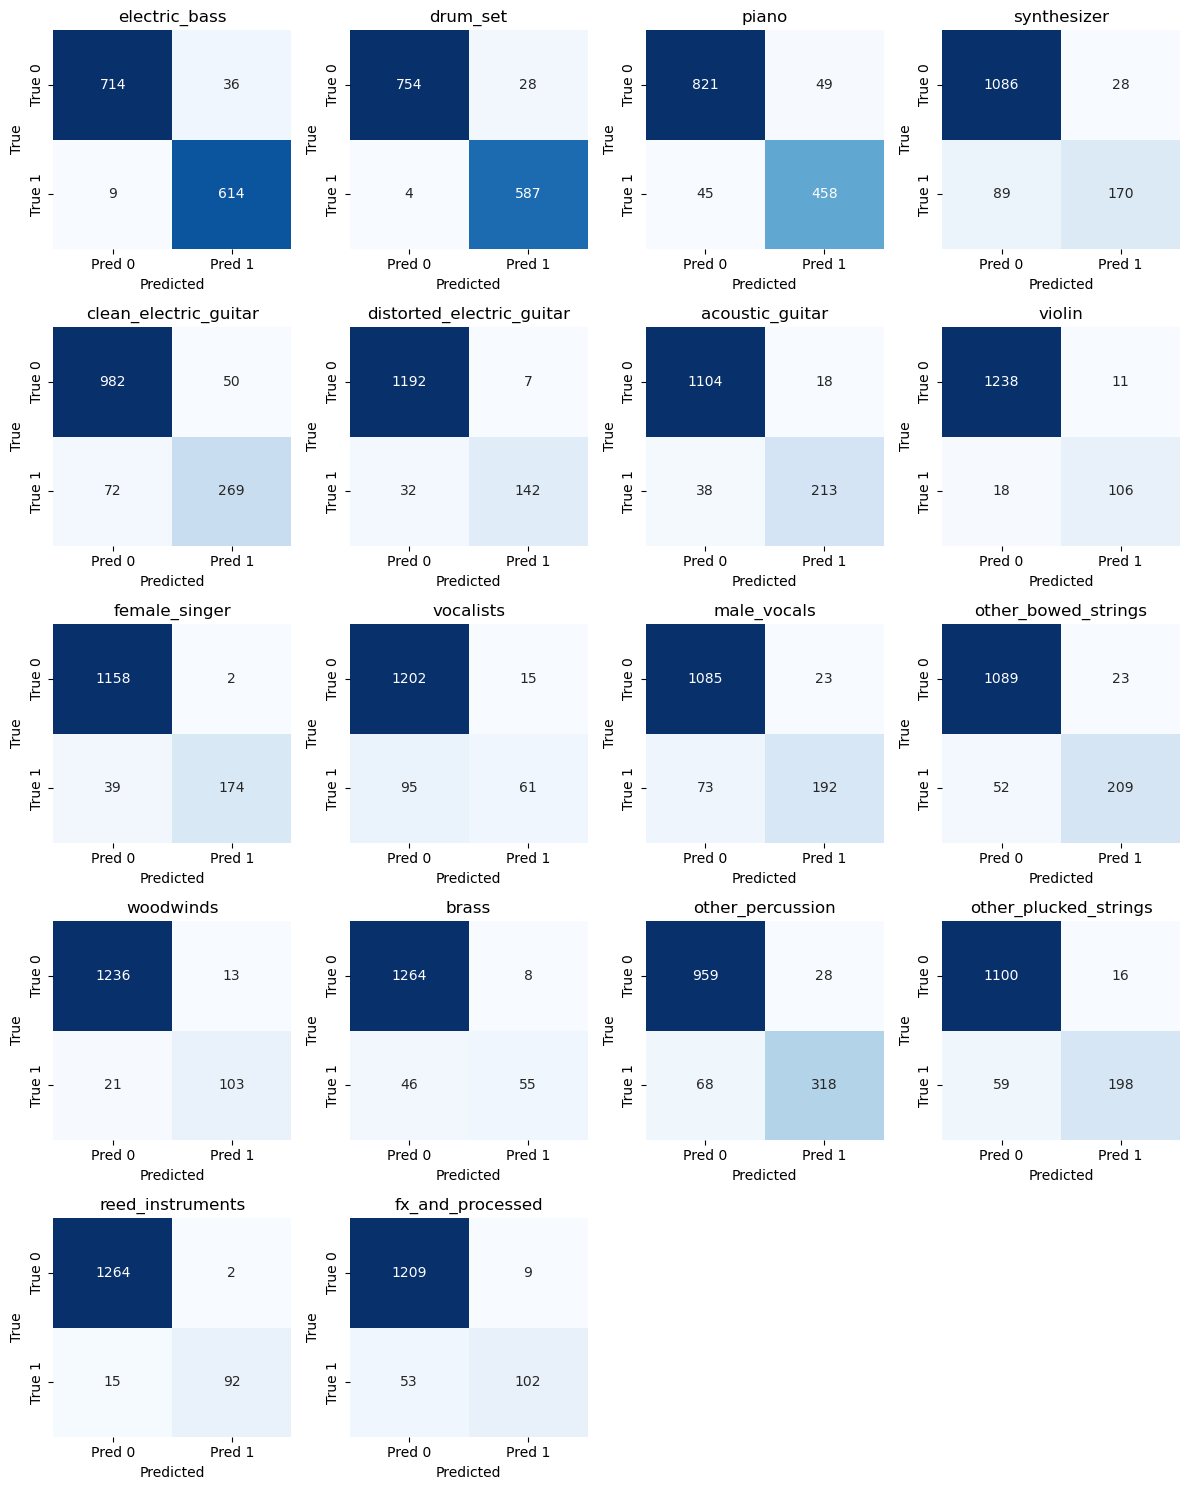

In [87]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_mix_mel.h5')

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

# Plot
num_classes = len(instrument_categories)
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(instrument_categories):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

Showing model 3 classification reports:

In [88]:
# Classification report for validation and test sets
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.94      0.99      0.96       623
           1       0.95      0.99      0.97       591
           2       0.90      0.91      0.91       503
           3       0.86      0.66      0.74       259
           4       0.84      0.79      0.82       341
           5       0.95      0.82      0.88       174
           6       0.92      0.85      0.88       251
           7       0.91      0.85      0.88       124
           8       0.99      0.82      0.89       213
           9       0.80      0.39      0.53       156
          10       0.89      0.72      0.80       265
          11       0.90      0.80      0.85       261
          12       0.89      0.83      0.86       124
          13       0.87      0.54      0.67       101
          14       0.92      0.82      0.87       386
          15       0.93      0.77      0.84       257
          16       0.98      0.86      0.92       107
          17       0.92    

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## Classes reduction

In this section, we study the classification capabilities cleaning ambiguous classes and merging too-similar classes.

Loading data and filtering classes:

In [89]:
# Load data
X = np.load("extracted_mix_features/all_mels.npy")
y = np.load("extracted_mix_features/all_labels.npy")

# Remove classes 3 ('synthesizer') and 17 ('fx_and_processed')
classes_to_remove = [3, 17]

# Filtr out unwanted classes from y
y_filtered = np.delete(y, classes_to_remove, axis=1)

# Create a mapping from categories to indices
idx_to_category = {v: k for k, v in category_to_idx.items()}

# Get labels ordered by index
ordered_labels = [idx_to_category[i] for i in range(len(idx_to_category))]

# Remove the unwanted classes from the ordered labels
for idx in sorted(classes_to_remove, reverse=True):
    del ordered_labels[idx]

# Classes to merge (by index after cleaning)
classes_to_merge = [7, 8, 9]
new_class_name = 'voices'

# Create new merged class column
merged_col = np.any(y_filtered[:, classes_to_merge], axis=1).astype(int)

# Remove columns of merged classes (except one, to keep position)
y_filtered = np.delete(y_filtered, classes_to_merge, axis=1)

# Add the new merged column at the end
y_final = np.concatenate([y_filtered, merged_col[:, np.newaxis]], axis=1)

# Update the ordered labels to reflect the new merged class
for idx in sorted(classes_to_merge, reverse=True):
    del ordered_labels[idx]

# Add the new class name to the end of the ordered labels
ordered_labels.append(new_class_name)

# Verification
print(f"Final shape of X:                       {X.shape}")
print(f"Final shape of y:                       {y_final.shape}")
print(f"Final labels ({len(ordered_labels)}):   {ordered_labels}")

Final shape of X:                       (9154, 96, 130)
Final shape of y:                       (9154, 14)
Final labels (14):   ['electric_bass', 'drum_set', 'piano', 'clean_electric_guitar', 'distorted_electric_guitar', 'acoustic_guitar', 'violin', 'other_bowed_strings', 'woodwinds', 'brass', 'other_percussion', 'other_plucked_strings', 'reed_instruments', 'voices']


Showing the new instruments distribution in the MedleyDB mixes, using 14 classes instead of 18:


Class distribution in the filtered dataset:
    electric_bass:               4100 samples (44.8%)
    drum_set:               3884 samples (42.4%)
    voices:               3402 samples (37.2%)
    piano:               3395 samples (37.1%)
    other_percussion:               2597 samples (28.4%)
    clean_electric_guitar:               2402 samples (26.2%)
    other_plucked_strings:               1767 samples (19.3%)
    other_bowed_strings:               1760 samples (19.2%)
    acoustic_guitar:               1526 samples (16.7%)
    distorted_electric_guitar:               1097 samples (12.0%)
    violin:               785 samples (8.6%)
    woodwinds:               750 samples (8.2%)
    reed_instruments:               750 samples (8.2%)
    brass:               653 samples (7.1%)


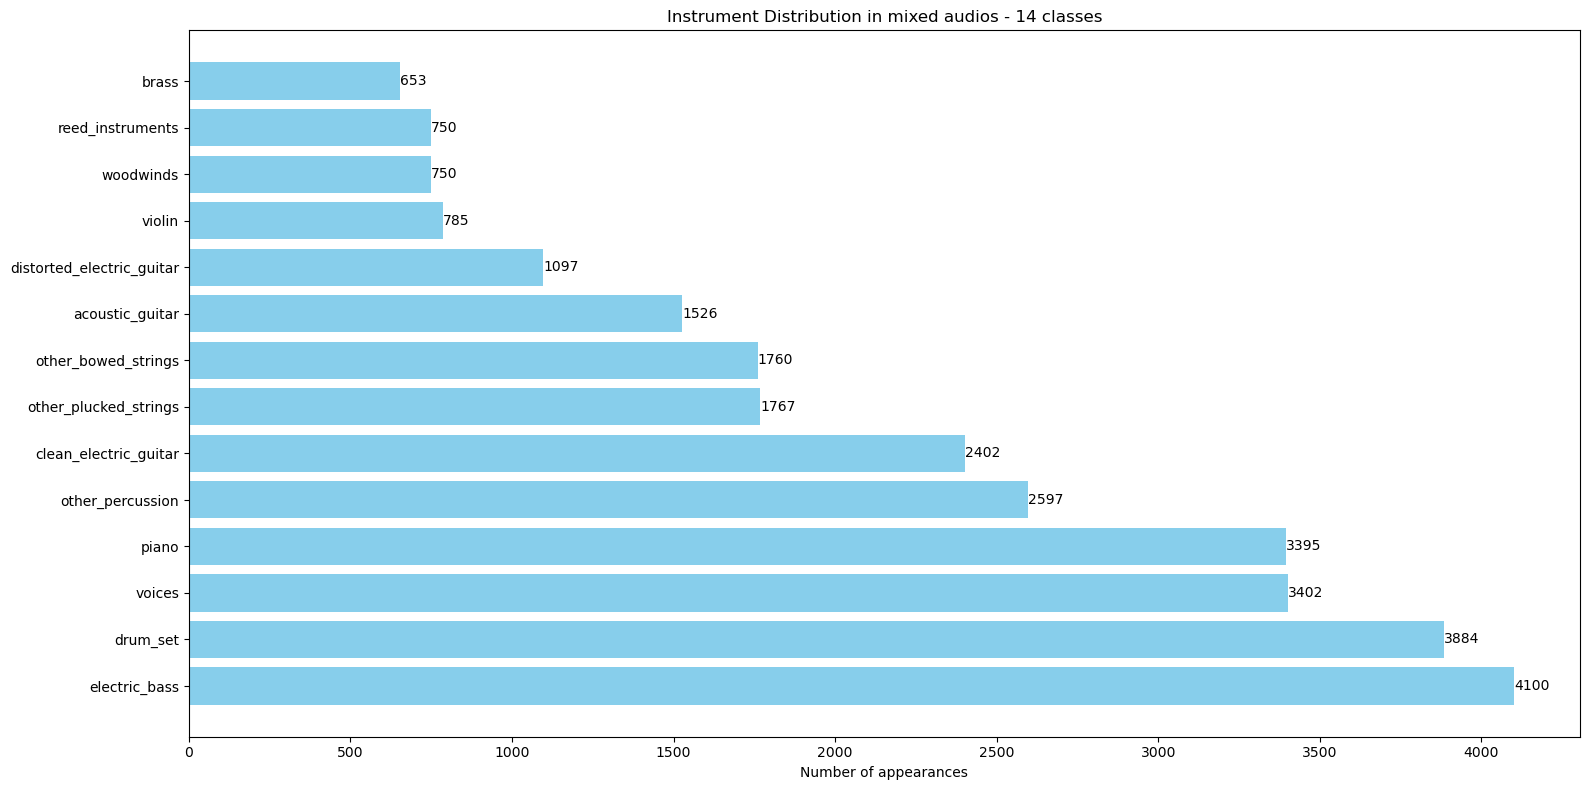


Dataset dimensions:
    X:                              (9154, 96, 130)
    Filtered y (multi-hot):         (9154, 14)
    Total samples:                  9154
    Current number of categories:   14


In [90]:
# Sum how many times each class appears (sum by columns)
class_counts = np.sum(y_final, axis=0)

# Create a dictionary in the format {category_name: count}
category_counts = {label: int(count) for label, count in zip(ordered_labels, class_counts)}

# Show the distribution
print("\nClass distribution in the filtered dataset:")
for category, count in sorted(category_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"    {category}:               {count} samples ({count / len(y_final) * 100:.1f}%)")

# Plot histogram
plot_instrument_histogram(category_counts, top_n=len(ordered_labels), title='Instrument Distribution in mixed audios - 14 classes')

# General summary
print(f"\nDataset dimensions:")
print(f"    X:                              {X.shape}")
print(f"    Filtered y (multi-hot):         {y_final.shape}")
print(f"    Total samples:                  {len(y_final)}")
print(f"    Current number of categories:   {len(ordered_labels)}")

## Model 4

Data splitting and normalization:

In [91]:
# Split into train, validation, and test sets
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y_final, test_size=0.1, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1.5/9, random_state=42
)

print(f"Loaded data: {cqt_features.shape}")

# Only on training set
mean = np.mean(X_train)
std = np.std(X_train)

# Normalize the data
X_train = (X_train - mean) / (std + 1e-6)
X_val = (X_val - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

Loaded data: (9154, 96, 130)


We take the same architecture  of model 2:

| Layer Type           | Details                                                        |
|:---------------------|:--------------------------------------------------------------|
| Input                | Input shape: (96, 130, 1)                                     |
| Conv2D               | Filters: **16**, Kernel: 3x3, Activation: relu, Padding: same |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| Conv2D               | Filters: **32**, Kernel: 3x3, Activation: relu, Padding: same |
| BatchNormalization   |                                                               |
| MaxPooling2D         | Pool size: 2x2                                                |
| GlobalAveragePooling2D |                                                            |
| Dense                | Units: **64**, Activation: relu                               |
| Dropout              | Rate: 0.4                                                     |
| Dense                | Units: 14, Activation: sigmoid                                |


In [ ]:
# 2D-CNN model for multi-label classification
input_shape = [X_train.shape[1], X_train.shape[2], 1]
num_classes = len(ordered_labels)

model = models.Sequential([
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', input_shape=input_shape),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'), 
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='sigmoid')
])

# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
               loss='binary_crossentropy',
               metrics=['binary_accuracy'])

# Print model summary
model.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_27 (Conv2D)          (None, 96, 130, 16)       160       
                                                                 
 batch_normalization_18 (Bat  (None, 96, 130, 16)      64        
 chNormalization)                                                
                                                                 
 max_pooling2d_24 (MaxPoolin  (None, 48, 65, 16)       0         
 g2D)                                                            
                                                                 
 conv2d_28 (Conv2D)          (None, 48, 65, 32)        4640      
                                                                 
 batch_normalization_19 (Bat  (None, 48, 65, 32)       128       
 chNormalization)                                                
                                                     

Training the model and saving history and weights in the files `training_model_mix_final.log` and `best_model_mix_final.h5`.

The code for this process is given in format of text in order to make the project runnable in reasonable time:

In [93]:
'''
# Callbacks for training
csv_logger = CSVLogger('training_model_mix_final.log', append=False)

early_stopping = EarlyStopping(monitor='val_loss', patience=70)

model_name = 'best_model_mix_final.h5'
model_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)

callbacks = [csv_logger, early_stopping, model_checkpoint]

# Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=400,
    batch_size=32,
    callbacks=callbacks
)
'''

"\n# Callbacks for training\ncsv_logger = CSVLogger('training_model_mix_final.log', append=False)\n\nearly_stopping = EarlyStopping(monitor='val_loss', patience=70)\n\nmodel_name = 'best_model_mix_final.h5'\nmodel_checkpoint = ModelCheckpoint(model_name, monitor='val_binary_accuracy', save_best_only=True, verbose=1)\n\ncallbacks = [csv_logger, early_stopping, model_checkpoint]\n\n# Train the model\nhistory = model.fit(\n    X_train, y_train,\n    validation_data=(X_val, y_val),\n    epochs=400,\n    batch_size=32,\n    callbacks=callbacks\n)\n"

Showing model 4 history:

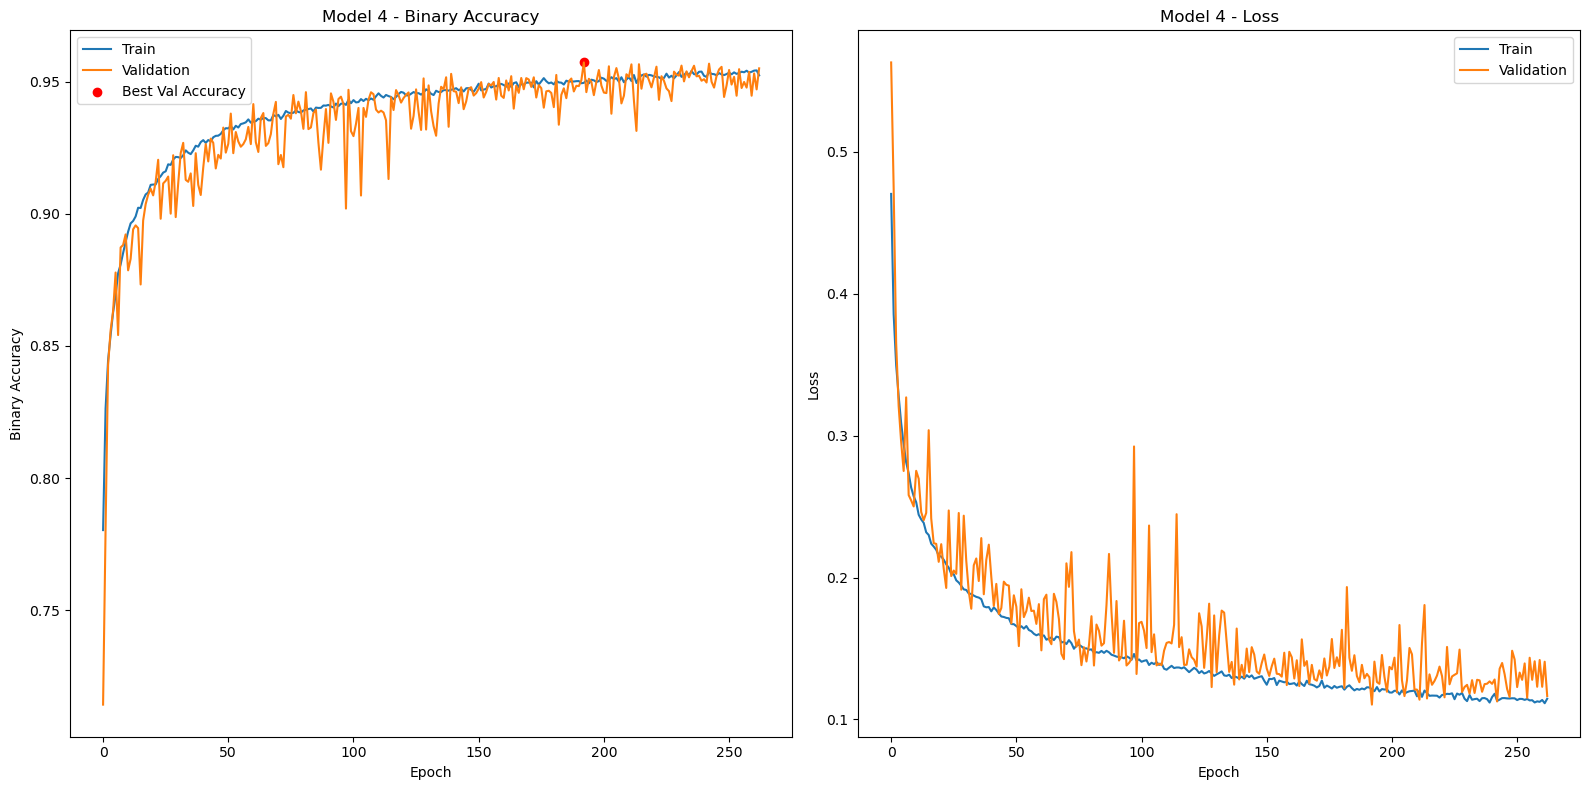

In [94]:
# History plot
log_df = pd.read_csv('training_model_mix_final.log')
best_val_acc = max(log_df['val_binary_accuracy'])
best_val_acc_epoch = log_df['epoch'][log_df['val_binary_accuracy'] == best_val_acc].values[0]

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(log_df['epoch'], log_df['binary_accuracy'], label='Train')
plt.plot(log_df['epoch'], log_df['val_binary_accuracy'], label='Validation')
plt.scatter(best_val_acc_epoch, best_val_acc, color='red', label='Best Val Accuracy')
plt.title('Model 4 - Binary Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Binary Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(log_df['epoch'], log_df['loss'], label='Train')
plt.plot(log_df['epoch'], log_df['val_loss'], label='Validation')
plt.title('Model 4 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Showing model 4 confusion matrixes:

29/29 [==============================] - 0s 2ms/step


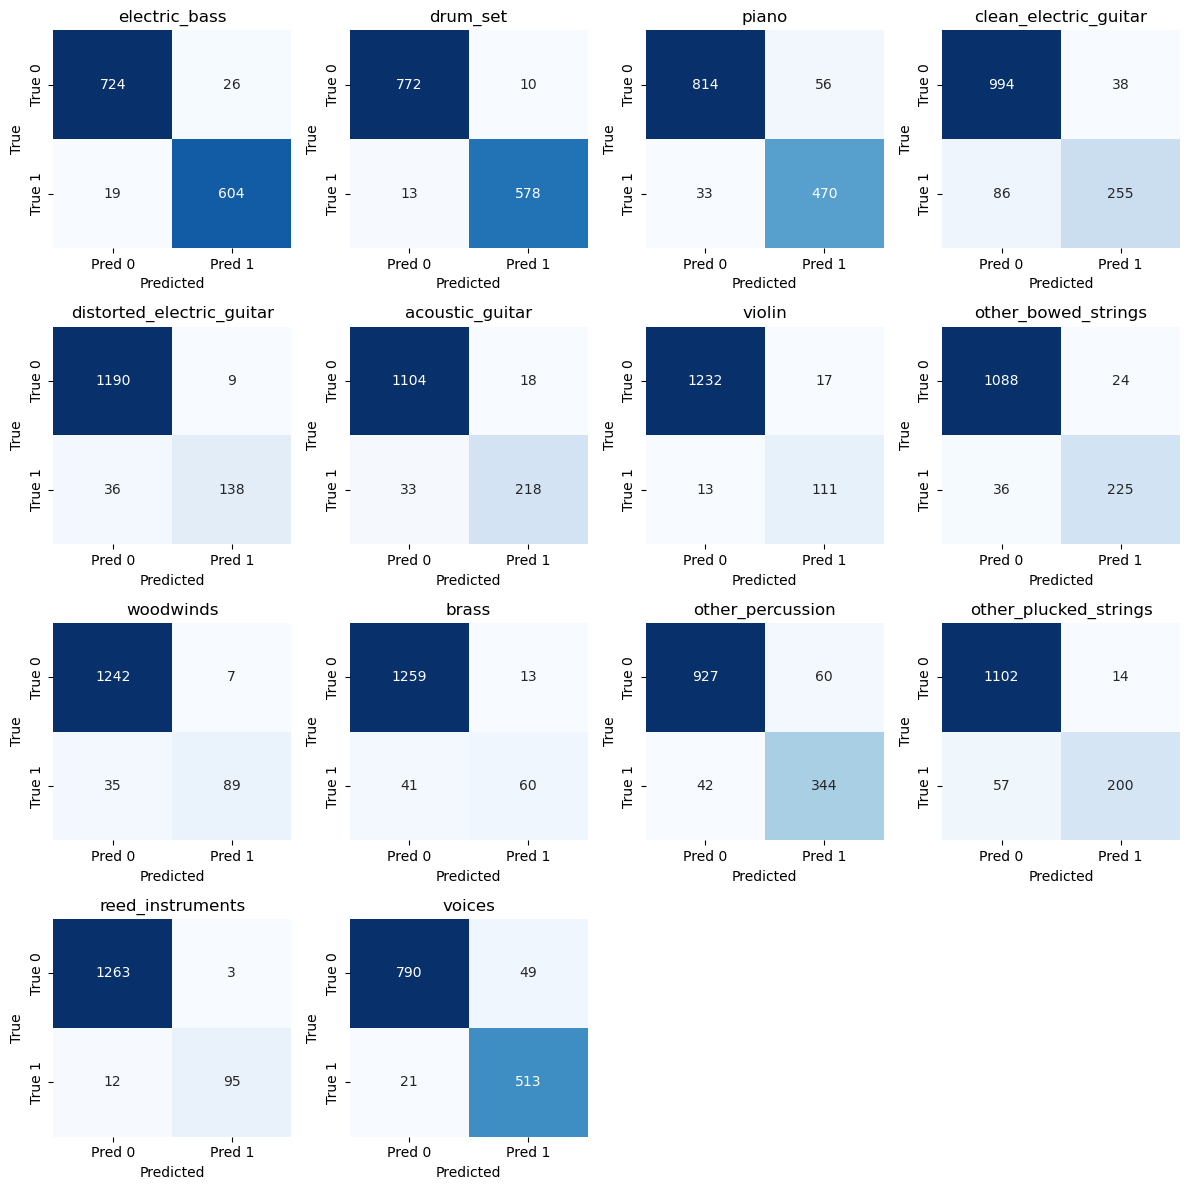

In [95]:
# Confusion matrix for validation and test sets
model.load_weights('best_model_mix_final.h5')

# Predict probabilities
y_val_pred_prob = model.predict(X_val)
y_test_pred_prob = model.predict(X_test)

# Binarize predictions (threshold = 0.5)
y_val_pred = (y_val_pred_prob >= 0.5).astype(int)
y_test_pred = (y_test_pred_prob >= 0.5).astype(int)

# Compute multilabel confusion matrices
val_cm = multilabel_confusion_matrix(y_val, y_val_pred)
test_cm = multilabel_confusion_matrix(y_test, y_test_pred)

# Plot
cols = 4  # Number of columns in the plot grid
rows = (num_classes + cols - 1) // cols

plt.figure(figsize=(3*cols, 3*rows))
for i, category in enumerate(ordered_labels):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(val_cm[i], annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    plt.title(category)
    plt.xlabel('Predicted')
    plt.ylabel('True')
plt.tight_layout()
plt.show()

Showing model 4 classification reports:

In [96]:
print(classification_report(y_val, y_val_pred))
print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

           0       0.96      0.97      0.96       623
           1       0.98      0.98      0.98       591
           2       0.89      0.93      0.91       503
           3       0.87      0.75      0.80       341
           4       0.94      0.79      0.86       174
           5       0.92      0.87      0.90       251
           6       0.87      0.90      0.88       124
           7       0.90      0.86      0.88       261
           8       0.93      0.72      0.81       124
           9       0.82      0.59      0.69       101
          10       0.85      0.89      0.87       386
          11       0.93      0.78      0.85       257
          12       0.97      0.89      0.93       107
          13       0.91      0.96      0.94       534

   micro avg       0.92      0.89      0.90      4377
   macro avg       0.91      0.85      0.88      4377
weighted avg       0.92      0.89      0.90      4377
 samples avg       0.91   

c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in samples with no true labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Giuliano\Documents\STMAE\.conda\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in samples with no true nor predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re